# 06 — DPO from scratch

## Learning objectives

- Derive optimal KL-regularized policy and implicit reward.
- Implement response-summed logps with causal shifting and masks.
- Train and validate a small GRU policy with a frozen reference.

This notebook runs a small CPU demonstration by default. Synthetic experiments are educational, not evidence of LLM alignment. Pretrained-model downloads and GPU training require explicit opt-in. All runtime outputs stay inside `RLHF_NOTEBOOKS/`.

**Source connection:** All three DPO source notebooks; final long sources identical, compact version has precision/template issues; notes Chapters05/09. Original handwritten8/3 versus108/103 reward offsets motivate cancellation.

[Learning order and setup](README.md).

In [1]:
from pathlib import Path
import os, sys, json, math, random, copy, re, subprocess, hashlib
# Find this collection when launched from the repository, module, or notebook directory.
candidates = [Path.cwd(), Path.cwd()/'RLHF_NOTEBOOKS', Path.cwd()/'13_rlhf_ppo_dpo_orpo/RLHF_NOTEBOOKS']
ROOT = next((p.resolve() for p in candidates if (p/'source_inspection.json').exists()), None)
if ROOT is None:
    raise RuntimeError('Launch Jupyter from RLHF_NOTEBOOKS, its parent, or the repository root.')
RUNTIME = ROOT/'runtime'; RUNTIME.mkdir(exist_ok=True)
os.environ['MPLCONFIGDIR'] = str(RUNTIME/'matplotlib')
os.environ['HF_HOME'] = str(RUNTIME/'huggingface')
os.environ['HF_DATASETS_CACHE'] = str(RUNTIME/'huggingface/datasets')
os.environ['TOKENIZERS_PARALLELISM'] = 'false'
os.environ['WANDB_DISABLED'] = 'true'
import numpy as np
import torch
from torch import nn
from torch.nn import functional as F
import matplotlib.pyplot as plt
random.seed(42); np.random.seed(42); torch.manual_seed(42)
torch.set_num_threads(1)
print('Python', sys.version.split()[0], 'PyTorch', torch.__version__, 'CUDA', torch.cuda.is_available())

Python 3.13.9 PyTorch 2.8.0+cpu CUDA False


## Derivation and symbols
For prompt $x$, maximize $\mathbb E_{y\sim\pi}r(x,y)-\beta D_{KL}(\pi\Vert\pi_{ref})$ subject to $\sum_y\pi(y\mid x)=1$. $r$ is scalar reward, $\beta>0$ KL coefficient, and $\pi_{ref}$ fixed supported reference. A Lagrange multiplier yields:

$$
\pi^*(y\mid x)=\frac{\pi_{ref}(y\mid x)e^{r(x,y)/\beta}}{Z(x)},\qquad r=\beta\log\frac{\pi^*}{\pi_{ref}}+\beta\log Z(x).
$$
$Z$ normalizes probabilities. Pairwise rewards for the same prompt cancel $\beta\log Z(x)$, so an explicit reward network is unnecessary.

$$
\mathcal L_{DPO}=-\mathbb E\log\sigma\left(\beta[(\ell_w-\ell_{ref,w})-(\ell_l-\ell_{ref,l})]\right).
$$
$w/l$ mean preferred/rejected responses, $\ell=\sum_t m_t\log\pi(y_t\mid x,y_{<t})$, and $m_t$ completion mask. Do not confuse this sum with ORPO mean logp. Both absolute likelihoods can fall while their relative margin improves. Increasing beta changes both derived regularization interpretation and logistic gradient scale; it is not universally beneficial.

In [2]:
def read_preferences():
    path = ROOT.parent/'reward_preferences_dataset.jsonl'
    if path.exists():
        raw = path.read_bytes(); origin = str(path)
    else:
        # Originals are currently missing from the working tree. Read their Git blob;
        # never restore, overwrite or silently substitute invented preference records.
        gitroot = Path(subprocess.check_output(['git','rev-parse','--show-toplevel'], cwd=ROOT, text=True).strip())
        rel = (ROOT.parent/'reward_preferences_dataset.jsonl').relative_to(gitroot).as_posix()
        raw = subprocess.check_output(['git','show','HEAD:'+rel], cwd=gitroot)
        origin = 'HEAD:'+rel
    expected = json.loads((ROOT/'source_inspection.json').read_text())
    digest = next(r['sha256'] for r in expected if r['source']=='reward_preferences_dataset.jsonl')
    assert hashlib.sha256(raw).hexdigest() == digest, 'Dataset changed: re-audit before proceeding'
    rows = [json.loads(line) for line in raw.decode('utf-8').splitlines()]
    for row in rows:
        assert set(row)=={'prompt','chosen','rejected'}
        assert all(isinstance(row[k],str) and row[k].strip() for k in row)
        assert row['chosen'].strip()!=row['rejected'].strip()
    assert len({r['prompt'].strip().lower() for r in rows})==len(rows)
    print('Dataset origin:',origin,'records:',len(rows),'fields:',list(rows[0]))
    return rows
rows = read_preferences()
indices = np.random.default_rng(42).permutation(len(rows))
train_rows = [rows[i] for i in indices[:14]]
valid_rows = [rows[i] for i in indices[14:17]]
test_rows = [rows[i] for i in indices[17:]]
assert not ({r['prompt'] for r in train_rows} & {r['prompt'] for r in valid_rows+test_rows})
print('Prompt-separated split:',len(train_rows),len(valid_rows),len(test_rows))

Dataset origin: HEAD:13_rlhf_ppo_dpo_orpo/reward_preferences_dataset.jsonl records: 20 fields: ['prompt', 'chosen', 'rejected']
Prompt-separated split: 14 3 3


## Causal labels and masking
Logits at position $j$ predict token $j+1$. Attention masks exclude padding from attention; completion masks exclude prompt/padding from the objective. EOS is scored once. Pad ID0 is separate from EOS2. Full-sequence character encoding avoids boundary merges; real BPE tokenizers require checking full prompt+completion boundaries and chat-template consistency.

In [3]:
# Character vocabulary: finite encoding avoids tokenizer downloads and boundary merges.
# This is an educational tokenizer, not a pretrained chat model's tokenizer.
CHARS = sorted(set(''.join(r[k] for r in rows for k in ('prompt','chosen','rejected'))+'Question: Answer:\n'))
vocab = {'<pad>':0,'<bos>':1,'<eos>':2,'<unk>':3, **{c:i+4 for i,c in enumerate(CHARS)}}
def encode(text): return [vocab.get(c,3) for c in text]
def pair_batch(examples, side):
    seqs=[]; response=[]
    for r in examples:
        prefix=[1]+encode('Question: '+r['prompt']+'\nAnswer: ')
        answer=encode(r[side])+[2]
        seqs.append(prefix+answer);response.append([0]*len(prefix)+[1]*len(answer))
    length=max(map(len,seqs))
    ids=torch.tensor([s+[0]*(length-len(s)) for s in seqs])
    attention=ids.ne(0)
    completion=torch.tensor([m+[0]*(length-len(m)) for m in response],dtype=torch.bool)
    return ids,attention,completion

def completion_logps(logits,ids,attention,completion,average=False):
    assert logits.shape[:2]==ids.shape==attention.shape==completion.shape
    target=ids[:,1:]
    assert (target>=0).all() and (target<logits.shape[-1]).all()
    active=completion[:,1:].bool() & attention[:,1:].bool() & attention[:,:-1].bool()
    counts=active.sum(-1)
    if (counts==0).any(): raise ValueError('Empty scored completion')
    selected=F.log_softmax(logits[:,:-1].float(),-1).gather(-1,target.unsqueeze(-1)).squeeze(-1)
    total=selected.masked_fill(~active,0).sum(-1)
    return total/counts if average else total

class TinyLM(nn.Module):
    def __init__(self):
        super().__init__();self.embedding=nn.Embedding(len(vocab),24,padding_idx=0)
        self.rnn=nn.GRU(24,32,batch_first=True);self.head=nn.Linear(32,len(vocab))
    def forward(self,ids): return self.head(self.rnn(self.embedding(ids))[0])

def score(model,batch,average=False):
    ids,att,mask=batch
    return completion_logps(model(ids),ids,att,mask,average)

def finite_step(loss,model,optimizer):
    assert torch.isfinite(loss).all()
    optimizer.zero_grad();loss.backward()
    grads=[p.grad for p in model.parameters() if p.requires_grad and p.grad is not None]
    assert grads and all(torch.isfinite(g).all() for g in grads)
    assert any(g.abs().sum()>0 for g in grads), 'No gradient signal'
    nn.utils.clip_grad_norm_(model.parameters(),1.0);optimizer.step()

# Meaningful causal-shift, prompt exclusion, padding and gradient tests.
ids=torch.tensor([[1,4,5,2,0]]); att=ids.ne(0);mask=torch.tensor([[0,0,1,1,0]],dtype=torch.bool)
logits=torch.zeros(1,5,len(vocab),requires_grad=True)
s=completion_logps(logits,ids,att,mask)
assert torch.allclose(s,torch.tensor([-2*math.log(len(vocab))]))
(-s.sum()).backward()
assert logits.grad[0,0].abs().sum()==0   # predicts masked prompt token
assert logits.grad[0,1:3].abs().sum()>0  # predicts response and EOS
assert logits.grad[0,3:].abs().sum()==0  # padding / unused last logits
assert torch.allclose(completion_logps(logits.detach(),ids,att,mask,True),s.detach()/2)
try:
    completion_logps(logits.detach(),ids,att,torch.zeros_like(mask))
    raise AssertionError('Should reject empty completions')
except ValueError: pass
print('Causal shifting, response/padding masking and gradient checks passed.')

Causal shifting, response/padding masking and gradient checks passed.


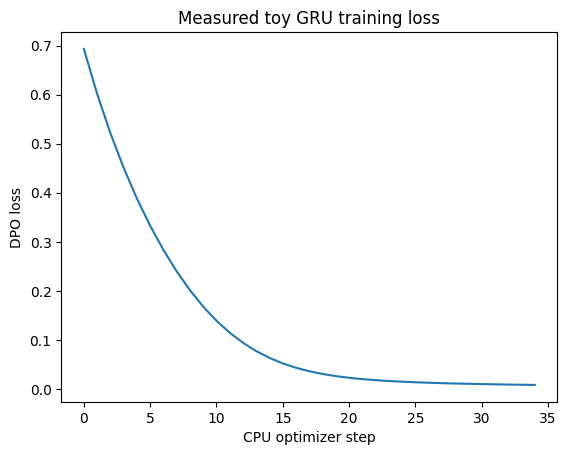

First/final training loss: 0.6931472420692444 0.008386478759348392


In [4]:
def dpo_loss(w,l,rw,rl,beta=.1):
    if beta<=0: raise ValueError('beta must be positive')
    margin=beta*((w-l)-(rw.detach()-rl.detach()))
    return F.softplus(-margin).mean(),margin
assert abs(dpo_loss(torch.zeros(1),torch.zeros(1),torch.zeros(1),torch.zeros(1))[0].item()-math.log(2))<1e-6
policy=TinyLM();reference=copy.deepcopy(policy).eval().requires_grad_(False)
chosen=pair_batch(train_rows,'chosen');rejected=pair_batch(train_rows,'rejected')
with torch.no_grad():rw=score(reference,chosen);rl=score(reference,rejected)
opt=torch.optim.Adam(policy.parameters(),lr=.003)
history=[]
for step in range(35):
    loss,margin=dpo_loss(score(policy,chosen),score(policy,rejected),rw,rl)
    finite_step(loss,policy,opt);history.append(loss.item())
assert all(p.grad is None for p in reference.parameters())
assert history[-1]<history[0]
plt.plot(history);plt.xlabel('CPU optimizer step');plt.ylabel('DPO loss');plt.title('Measured toy GRU training loss');plt.show()
print('First/final training loss:',history[0],history[-1])

In [5]:
@torch.no_grad()
def evaluate_pairs(model,examples,reference=None):
    model.eval();w=score(model,pair_batch(examples,'chosen'));l=score(model,pair_batch(examples,'rejected'))
    raw=w-l;out={'raw_preference_accuracy':raw.gt(0).float().mean().item(),'chosen_mean_sum_logp':w.mean().item(),'rejected_mean_sum_logp':l.mean().item()}
    if reference is not None:
        relative=raw-(score(reference,pair_batch(examples,'chosen'))-score(reference,pair_batch(examples,'rejected')))
        out['relative_margin_mean']=relative.mean().item()
        out['reference_adjusted_accuracy']=relative.gt(0).float().mean().item()
    return out
print('Train:',evaluate_pairs(policy,train_rows,reference))
print('Validation:',evaluate_pairs(policy,valid_rows,reference))
policy.train()

Train: {'raw_preference_accuracy': 0.0, 'chosen_mean_sum_logp': -316.3367614746094, 'rejected_mean_sum_logp': -210.70858764648438, 'relative_margin_mean': 52.25266647338867, 'reference_adjusted_accuracy': 1.0}
Validation: {'raw_preference_accuracy': 0.0, 'chosen_mean_sum_logp': -303.2361755371094, 'rejected_mean_sum_logp': -176.526123046875, 'relative_margin_mean': 41.9420166015625, 'reference_adjusted_accuracy': 1.0}


TinyLM(
  (embedding): Embedding(55, 24, padding_idx=0)
  (rnn): GRU(24, 32, batch_first=True)
  (head): Linear(in_features=32, out_features=55, bias=True)
)

## Exercises

1. Verify reference gradients remain absent after every update.
2. Replace response-summed logps with means and explain why the objective changes.
3. Create noisy pairs and compare validation loss versus raw chosen likelihood.

## Key takeaways

Recompute the worked examples, inspect masks and gradients, and evaluate independently of the training objective. A small training-loss decrease does not establish generalization or alignment. Record the model, data split, seeds and dependency versions before interpreting results.